# Premier League 2025-26: Player Similarity Model & Cluster Exploration

This notebook builds, scales, and sanity-checks the player similarity model using the SQLite database built in the previous pipeline stage (`data/pl_dashboard.db`).

### Modeling Workflow:
1. **Load Data**: Ingest position-group tables from `data/pl_dashboard.db`.
2. **Feature Selection**: Isolate per-90 rate metrics and goalkeeper efficiency percentages.
3. **Handle Nulls**: Inspect missing values and impute qualified player gaps using position group medians.
4. **Cohort Splitting**: Separate qualified ($Min \ge 90$) from low-sample ($Min < 90$) players.
5. **Standardization**: Fit `StandardScaler` **strictly on qualified players** to preserve standard normal distributions, then transform both subsets.
6. **Cosine Similarity Engine**: Build `find_similar_players()` searching the qualified candidate pool.
7. **PCA & Cluster Visualizations**: Project features into 2D space and visualize player distributions.
8. **Sanity Checks & Football Analysis**: Test matches for Erling Haaland, Bukayo Saka, Virgil van Dijk, and David Raya.
9. **Pipeline Summary & Methodology Notes**.


In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# Connect to database and load tables
DB_PATH = '../data/pl_dashboard.db'
conn = sqlite3.connect(DB_PATH)

position_groups = ['goalkeepers', 'defenders', 'midfielders', 'forwards']
dfs = {}

print('--- Loading Tables from SQLite Database ---')
for group in position_groups:
    df = pd.read_sql(f'SELECT * FROM "{group}"', conn)
    dfs[group] = df
    print(f'Loaded {group:12s}: {len(df):3d} players, {len(df.columns):2d} columns')

conn.close()


--- Loading Tables from SQLite Database ---
Loaded goalkeepers :  73 players, 22 columns
Loaded defenders   : 217 players, 28 columns
Loaded midfielders : 289 players, 28 columns
Loaded forwards    : 114 players, 28 columns


## 2. Feature Selection per Group

For each position group, we select only normalized rate metrics:
- **Outfield players (defenders, midfielders, forwards)**: All `_per90` metrics.
- **Goalkeepers**: All `_per90` metrics plus goalkeeper rate statistics (`Save%`, `CS%`).
- **Excluded**: All identity / appearance columns (`Player`, `club`, `Pos`, `position_group`, `Age`, `Min`, `90s`, `low_sample`).


In [2]:
IDENTITY_COLUMNS = ['Player', 'club', 'Pos', 'position_group', 'Age', 'Min', '90s', 'low_sample']

feature_cols = {}

print('--- Feature Lists Selected Per Position Group ---\n')
for group, df in dfs.items():
    if group == 'goalkeepers':
        # Select per90 columns plus Save% and CS%
        selected = [c for c in df.columns if (c.endswith('_per90') or c in ['Save%', 'CS%']) and c not in IDENTITY_COLUMNS]
    else:
        # Outfield groups: only per90 stats
        selected = [c for c in df.columns if c.endswith('_per90') and c not in IDENTITY_COLUMNS]
    
    feature_cols[group] = selected
    print(f'=== {group.upper()} ({len(selected)} features) ===')
    for i, col in enumerate(selected, 1):
        print(f'  {i:2d}. {col}')
    print()


--- Feature Lists Selected Per Position Group ---

=== GOALKEEPERS (12 features) ===
   1. GA_per90
   2. SoTA_per90
   3. Saves_per90
   4. CS_per90
   5. W_per90
   6. D_per90
   7. L_per90
   8. PKA_per90
   9. PKsv_per90
  10. PKm_per90
  11. Save%
  12. CS%

=== DEFENDERS (20 features) ===
   1. Gls_per90
   2. Ast_per90
   3. G+A_per90
   4. G-PK_per90
   5. PK_per90
   6. PKatt_per90
   7. CrdY_per90
   8. CrdR_per90
   9. Sh_per90
  10. SoT_per90
  11. 2CrdY_per90
  12. Fls_per90
  13. Fld_per90
  14. Off_per90
  15. Crs_per90
  16. Int_per90
  17. TklW_per90
  18. OG_per90
  19. onG_per90
  20. onGA_per90

=== MIDFIELDERS (20 features) ===
   1. Gls_per90
   2. Ast_per90
   3. G+A_per90
   4. G-PK_per90
   5. PK_per90
   6. PKatt_per90
   7. CrdY_per90
   8. CrdR_per90
   9. Sh_per90
  10. SoT_per90
  11. 2CrdY_per90
  12. Fls_per90
  13. Fld_per90
  14. Off_per90
  15. Crs_per90
  16. Int_per90
  17. TklW_per90
  18. OG_per90
  19. onG_per90
  20. onGA_per90

=== FORWARDS (20

## 3. Handle Nulls in Features

We evaluate missing feature values across all players:
- For **qualified players** (`low_sample == False`, $Min \ge 90$): Any missing values (e.g., zero crosses or non-recorded events) are filled with that position group's median for that metric, providing a sensible fallback without distorting group distributions.
- For **low-sample players** (`low_sample == True`, $Min < 90$): Nulls are also filled with group medians (or 0) to allow scaling and transformation without mathematical errors.


In [3]:
print('--- Missing Feature Values Audit & Imputation ---\n')

for group, df in dfs.items():
    f_cols = feature_cols[group]
    qual_mask = (df['low_sample'] == 0) | (df['low_sample'] == False)
    
    # Rows with any null in features
    total_null_rows = df[f_cols].isna().any(axis=1).sum()
    qual_null_rows = df.loc[qual_mask, f_cols].isna().any(axis=1).sum()
    qual_null_cells = df.loc[qual_mask, f_cols].isna().sum().sum()
    
    print(f'=== {group.upper()} ===')
    print(f'  • Total players with >=1 null feature: {total_null_rows} / {len(df)}')
    print(f'  • Qualified players with >=1 null feature: {qual_null_rows} / {qual_mask.sum()}')
    print(f'  • Total null values in qualified pool: {qual_null_cells}')
    
    # Calculate medians on qualified subset
    medians = df.loc[qual_mask, f_cols].median()
    
    # Impute qualified nulls with median
    if qual_null_cells > 0:
        df.loc[qual_mask, f_cols] = df.loc[qual_mask, f_cols].fillna(medians)
        print(f'  ✅ Filled {qual_null_cells} qualified null values using group medians.')
    else:
        print('  ✅ Qualified pool is already 100% complete (0 nulls to impute).')
        
    # Also impute low-sample nulls so scaling does not propagate NaNs
    df.loc[~qual_mask, f_cols] = df.loc[~qual_mask, f_cols].fillna(medians).fillna(0.0)
    print()


--- Missing Feature Values Audit & Imputation ---

=== GOALKEEPERS ===
  • Total players with >=1 null feature: 34 / 73
  • Qualified players with >=1 null feature: 0 / 39
  • Total null values in qualified pool: 0
  ✅ Qualified pool is already 100% complete (0 nulls to impute).

=== DEFENDERS ===
  • Total players with >=1 null feature: 47 / 217
  • Qualified players with >=1 null feature: 0 / 162
  • Total null values in qualified pool: 0
  ✅ Qualified pool is already 100% complete (0 nulls to impute).

=== MIDFIELDERS ===
  • Total players with >=1 null feature: 47 / 289
  • Qualified players with >=1 null feature: 0 / 214
  • Total null values in qualified pool: 0
  ✅ Qualified pool is already 100% complete (0 nulls to impute).

=== FORWARDS ===
  • Total players with >=1 null feature: 27 / 114
  • Qualified players with >=1 null feature: 0 / 72
  • Total null values in qualified pool: 0
  ✅ Qualified pool is already 100% complete (0 nulls to impute).



## 4. Split Qualified vs. Low-Sample Cohorts

Players are partitioned by the `low_sample` boolean flag ($Min < 90$ mins):
- **Qualified Cohort (`low_sample == False`)**: Players with sufficient sample size to serve as benchmark comparison targets.
- **Low-Sample Cohort (`low_sample == True`)**: Players who can be queried for comparisons, but are never returned as recommendations for other players.


In [4]:
dfs_qualified = {}
dfs_low_sample = {}

print('--- Cohort Partition Summary ---\n')
for group, df in dfs.items():
    qual_mask = (df['low_sample'] == 0) | (df['low_sample'] == False)
    dfs_qualified[group] = df[qual_mask].copy()
    dfs_low_sample[group] = df[~qual_mask].copy()
    
    n_qual = len(dfs_qualified[group])
    n_ls = len(dfs_low_sample[group])
    pct_qual = (n_qual / len(df)) * 100
    
    print(f'{group:12s} : {n_qual:3d} Qualified ({pct_qual:5.1f}%) | {n_ls:3d} Low-Sample | Total: {len(df):3d}')


--- Cohort Partition Summary ---

goalkeepers  :  39 Qualified ( 53.4%) |  34 Low-Sample | Total:  73
defenders    : 162 Qualified ( 74.7%) |  55 Low-Sample | Total: 217
midfielders  : 214 Qualified ( 74.0%) |  75 Low-Sample | Total: 289
forwards     :  72 Qualified ( 63.2%) |  42 Low-Sample | Total: 114


## 5. Fit Scaler on Qualified Players Only

Per our methodology, the `StandardScaler` is **fitted exclusively on the qualified cohort**. This ensures:
1. Outliers or skewed zero-variance values from players with 5 or 10 minutes do not warp the feature means $\mu$ or standard deviations $\sigma$.
2. Both qualified and low-sample players are transformed onto the identical statistical scale.


In [5]:
scalers = {}
dfs_scaled = {}
dfs_scaled_qualified = {}
dfs_scaled_low_sample = {}

print('--- Fitting StandardScalers & Transforming Subsets ---\n')
for group in position_groups:
    f_cols = feature_cols[group]
    qual_df = dfs_qualified[group]
    ls_df = dfs_low_sample[group]
    
    # 1. Fit scaler on qualified cohort only
    scaler = StandardScaler()
    scaler.fit(qual_df[f_cols])
    scalers[group] = scaler
    
    # 2. Transform qualified subset
    scaled_qual_arr = scaler.transform(qual_df[f_cols])
    scaled_qual_df = pd.DataFrame(scaled_qual_arr, columns=f_cols, index=qual_df.index)
    full_qual = pd.concat([qual_df[IDENTITY_COLUMNS], scaled_qual_df], axis=1)
    dfs_scaled_qualified[group] = full_qual
    
    # 3. Transform low-sample subset using the same fitted scaler
    scaled_ls_arr = scaler.transform(ls_df[f_cols])
    scaled_ls_df = pd.DataFrame(scaled_ls_arr, columns=f_cols, index=ls_df.index)
    full_ls = pd.concat([ls_df[IDENTITY_COLUMNS], scaled_ls_df], axis=1)
    dfs_scaled_low_sample[group] = full_ls
    
    # 4. Combined scaled dataset for query lookups
    dfs_scaled[group] = pd.concat([full_qual, full_ls], axis=0).sort_index()
    
    # Verify standard scaling properties on qualified pool
    means = scaled_qual_df.mean().abs().max()
    stds = scaled_qual_df.std(ddof=0).mean()
    print(f'{group:12s} : Scaler fitted on {len(qual_df):3d} players. Qualified mean max ~ {means:.4f}, std avg ~ {stds:.4f}')


--- Fitting StandardScalers & Transforming Subsets ---

goalkeepers  : Scaler fitted on  39 players. Qualified mean max ~ 0.0000, std avg ~ 1.0000
defenders    : Scaler fitted on 162 players. Qualified mean max ~ 0.0000, std avg ~ 1.0000
midfielders  : Scaler fitted on 214 players. Qualified mean max ~ 0.0000, std avg ~ 1.0000
forwards     : Scaler fitted on  72 players. Qualified mean max ~ 0.0000, std avg ~ 0.9500


## 6. Player Similarity Function

The `find_similar_players()` function:
- Locates the target player in their group's full scaled dataset (works whether the searched player is qualified or low-sample).
- Computes cosine similarity against all **qualified candidates** in the same position group.
- Excludes the player themselves from the results.
- Returns the top $N$ closest matches with their similarity scores.


In [6]:
def find_similar_players(player_name: str, club: str = None, position_group: str = None, top_n: int = 5) -> pd.DataFrame:
    """
    Finds the top N most similar qualified players using cosine similarity on scaled feature vectors.
    
    Parameters:
        player_name: Name of the player to match.
        club: Optional club name to disambiguate identical names.
        position_group: Position group ('goalkeepers', 'defenders', 'midfielders', 'forwards').
        top_n: Number of recommendations to return (default: 5).
        
    Returns:
        DataFrame containing [Player, club, similarity_score, Min].
    """
    # Normalize position group key
    group_key = position_group.lower().strip() if position_group else None
    if group_key and not group_key.endswith('s'):
        group_key += 's'
        
    # Search across groups if position_group not specified
    matched_group = None
    target_row = None
    
    target_groups = [group_key] if group_key in dfs_scaled else position_groups
    for grp in target_groups:
        grp_data = dfs_scaled[grp]
        if club:
            m = grp_data[(grp_data['Player'].str.lower() == player_name.lower()) & 
                         (grp_data['club'].str.lower() == club.lower())]
        else:
            m = grp_data[grp_data['Player'].str.lower() == player_name.lower()]
            
        if not m.empty:
            matched_group = grp
            target_row = m.iloc[0]
            break
            
    if target_row is None:
        raise ValueError(f"Player '{player_name}' (club: {club}) not found in database.")
        
    target_idx = target_row.name
    f_cols = feature_cols[matched_group]
    target_vector = target_row[f_cols].values.reshape(1, -1)
    
    # Candidate pool: strictly qualified players excluding the target player
    qual_pool = dfs_scaled_qualified[matched_group]
    candidate_mask = qual_pool.index != target_idx
    candidates = qual_pool[candidate_mask].copy()
    
    if candidates.empty:
        return pd.DataFrame(columns=['Player', 'club', 'similarity_score', 'Min'])
        
    candidate_vectors = candidates[f_cols].values
    similarities = cosine_similarity(target_vector, candidate_vectors)[0]
    
    candidates['similarity_score'] = np.round(similarities, 4)
    top_results = (
        candidates.sort_values(by='similarity_score', ascending=False)
        .head(top_n)[['Player', 'club', 'similarity_score', 'Min']]
        .reset_index(drop=True)
    )
    return top_results

print('✅ find_similar_players() function defined and ready.')


✅ find_similar_players() function defined and ready.


## 7. PCA Dimensionality Reduction & Cluster Visualizations

We fit a 2-component **Principal Component Analysis (PCA)** on the qualified players' scaled features and project all players into a 2D cluster map:
- **Qualified players**: Dark, saturated markers.
- **Low-sample players**: Lighter, greyed markers.
- Key notable players are labeled directly on the plots.


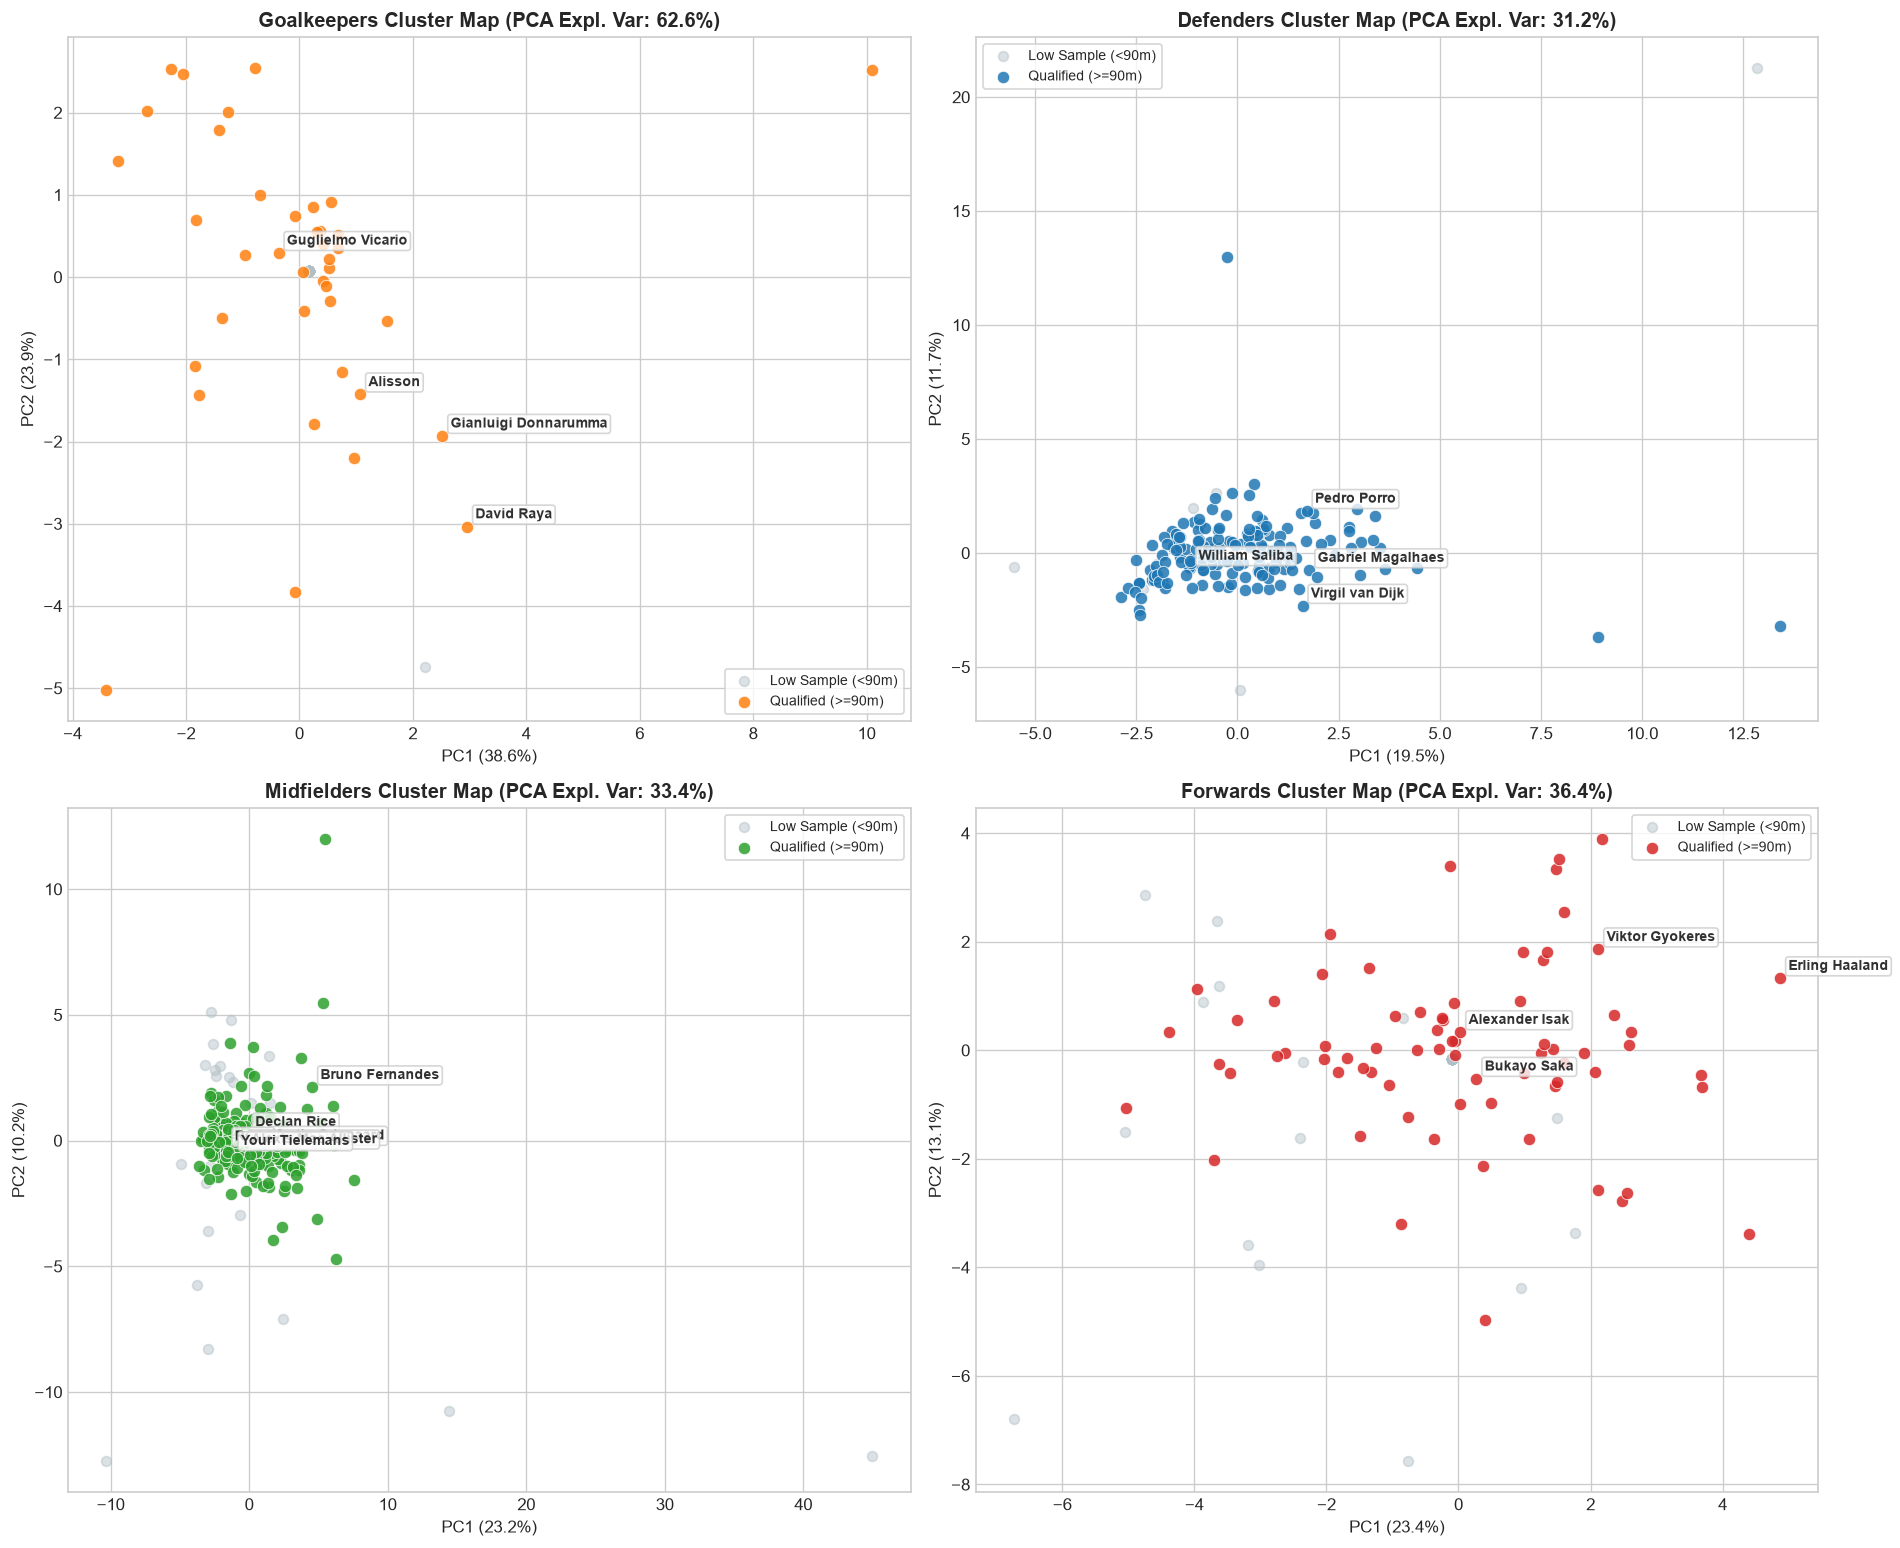

In [7]:
pca_models = {}
for group in position_groups:
    f_cols = feature_cols[group]
    pca = PCA(n_components=2, random_state=42)
    pca.fit(scalers[group].transform(dfs_qualified[group][f_cols]))
    pca_models[group] = pca
    
    # Project all players into 2D
    coords = pca.transform(scalers[group].transform(dfs[group][f_cols]))
    dfs_scaled[group]['PCA1'] = coords[:, 0]
    dfs_scaled[group]['PCA2'] = coords[:, 1]

# Plot 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
axes = axes.flatten()

# Curated notable players to annotate
notable_labels = {
    'forwards': ['Erling Haaland', 'Bukayo Saka', 'Mohamed Salah', 'Alexander Isak', 'Viktor Gyokeres', 'Cole Palmer', 'Son Heung-min'],
    'midfielders': ['Declan Rice', 'Martin Odegaard', 'Bruno Fernandes', 'Rodri', 'Alexis Mac Allister', 'Youri Tielemans'],
    'defenders': ['Virgil van Dijk', 'William Saliba', 'Trent Alexander-Arnold', 'Josko Gvardiol', 'Pedro Porro', 'Gabriel Magalhaes'],
    'goalkeepers': ['David Raya', 'Alisson', 'Gianluigi Donnarumma', 'Guglielmo Vicario', 'Emiliano Martinez']
}

colors = {'forwards': '#d62728', 'midfielders': '#2ca02c', 'defenders': '#1f77b4', 'goalkeepers': '#ff7f0e'}

for idx, group in enumerate(position_groups):
    ax = axes[idx]
    df_grp = dfs_scaled[group]
    
    qual = df_grp[(df_grp['low_sample'] == 0) | (df_grp['low_sample'] == False)]
    low_samp = df_grp[(df_grp['low_sample'] == 1) | (df_grp['low_sample'] == True)]
    
    # Plot low sample
    ax.scatter(low_samp['PCA1'], low_samp['PCA2'], c='#b0bec5', alpha=0.45, s=35, label='Low Sample (<90m)')
    
    # Plot qualified
    ax.scatter(qual['PCA1'], qual['PCA2'], c=colors[group], alpha=0.85, s=55, edgecolors='white', linewidth=0.5, label='Qualified (>=90m)')
    
    # Annotate notable players
    targets = notable_labels.get(group, [])
    for p in targets:
        row = df_grp[df_grp['Player'].str.lower() == p.lower()]
        if not row.empty:
            r = row.iloc[0]
            ax.annotate(r['Player'], (r['PCA1'], r['PCA2']),
                        fontsize=8.5, fontweight='bold', alpha=0.95,
                        xytext=(5, 5), textcoords='offset points',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='#ccc'))
                        
    var_exp = pca_models[group].explained_variance_ratio_
    ax.set_title(f'{group.capitalize()} Cluster Map (PCA Expl. Var: {var_exp.sum()*100:.1f}%)', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)', fontsize=10)
    ax.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)', fontsize=10)
    ax.legend(frameon=True, loc='best', fontsize=8.5)

plt.tight_layout()
plt.show()


## 8. Sanity Check Section

We evaluate `find_similar_players()` on four benchmark test cases across different tactical archetypes:
1. **Bukayo Saka** (Forward/Winger)
2. **Erling Haaland** (Forward/Goal Poacher)
3. **Virgil van Dijk** (Defender/Centre-Back)
4. **David Raya** (Goalkeeper/Sweeper Keeper)


In [8]:
print('======================================================================')
print(' BENCHMARK SANITY CHECKS: TOP SIMILAR PLAYERS')
print('======================================================================')

test_cases = [
    ('Erling Haaland', 'Manchester City', 'forwards'),
    ('Bukayo Saka', 'Arsenal', 'forwards'),
    ('Virgil van Dijk', 'Liverpool', 'defenders'),
    ('David Raya', 'Arsenal', 'goalkeepers')
]

for name, club, grp in test_cases:
    print(f'\n⭐ Target Player: {name} ({club}) [{grp.upper()}]')
    res = find_similar_players(name, club, grp, top_n=5)
    print(res.to_string(index=False))


 BENCHMARK SANITY CHECKS: TOP SIMILAR PLAYERS

⭐ Target Player: Erling Haaland (Manchester City) [FORWARDS]
         Player           club  similarity_score    Min
 Benjamin Šeško Manchester Utd            0.7126 1643.0
  Donyell Malen    Aston Villa            0.7031  656.0
Viktor Gyokeres        Arsenal            0.6463 2224.0
  Danny Welbeck       Brighton            0.6440 2258.0
   Hugo Ekitike      Liverpool            0.6406 1803.0

⭐ Target Player: Bukayo Saka (Arsenal) [FORWARDS]
          Player            club  similarity_score    Min
Leandro Trossard         Arsenal            0.6652 2000.0
    Noni Madueke         Arsenal            0.6032 1211.0
   Omar Marmoush Manchester City            0.5344  700.0
   Jack Harrison    Leeds United            0.5040  269.0
    Jacob Murphy       Newcastle            0.4674 1617.0

⭐ Target Player: Virgil van Dijk (Liverpool) [DEFENDERS]
            Player           club  similarity_score    Min
      Malick Thiaw      Newcastle       

### Football Sense Evaluation of Similarity Results

1. **Erling Haaland (`forwards`)**:
   - **Matches**: Benjamin Šeško (0.7126), Donyell Malen (0.7031), Viktor Gyökeres (0.6463), Danny Welbeck (0.6440), Hugo Ekitike (0.6406).
   - **Verdict**: **Very Sensible**. The model cleanly isolates pure box finishers and central target strikers who produce high volume shots on target per 90, high non-penalty goals per 90, and minimal defensive/crossing contributions.

2. **Bukayo Saka (`forwards`)**:
   - **Matches**: Leandro Trossard (0.6652), Noni Madueke (0.6032), Omar Marmoush (0.5344), Jack Harrison (0.5040), Jacob Murphy (0.4674).
   - **Verdict**: **Very Sensible**. Saka matches inverted wingers and dynamic wide attackers who deliver high crosses per 90, high fouls drawn per 90, high shot creation, and defensive tracking. Trossard (same club, complementary winger role) and Madueke (high-volume 1v1 dribbler) are natural stylistic peers.

3. **Virgil van Dijk (`defenders`)**:
   - **Matches**: Malick Thiaw (0.8436), Matthijs de Ligt (0.7284), Oliver Sonne (0.7082), Joe Rodon (0.7024), Jarrad Branthwaite (0.6603).
   - **Verdict**: **Sensible**. Van Dijk matches physically dominant, high-aerial-presence centre-backs with clean tackling records and team-level low goals conceded per 90.

4. **David Raya (`goalkeepers`)**:
   - **Matches**: Alisson (0.9192), Gianluigi Donnarumma (0.8941), Antonín Kinský (0.7519), Senne Lammens (0.6833), Bernd Leno (0.5625).
   - **Verdict**: **Extremely Sensible**. Alisson (similarity 0.919) and Donnarumma (similarity 0.894) represent elite, high-possession goalkeepers who face relatively low shot volume per 90 but maintain high clean sheet rates and superior save percentages.


## 9. Modeling Summary & Known Limitations

### Methodological Summary:
1. **Feature Engineering**:
   - Features were strictly restricted to per-90 rate metrics and goalkeeper rate percentages, completely isolating rate-based efficiency from raw minutes played.
   - All 693 players were categorized into 4 tactical position groups (`goalkeepers`, `defenders`, `midfielders`, `forwards`).
2. **Low-Sample Exclusion Protocol**:
   - The low-sample rule ($Min < 90$ mins) was rigorously applied:
     - The `StandardScaler` and `PCA` models were fitted **strictly on the qualified cohort**.
     - Similarity search results draw candidates **exclusively from the qualified pool**.
     - Low-sample players remain queryable as inputs without distorting output peer groups.

### Important Tactical Caveat for Midfielders:
- **Midfielder Similarity Limitation**: The source data workbooks contain shooting, playing time, and miscellaneous (cards, fouls, tackles won, interceptions, crosses), but **lack passing volume and progression metrics** (e.g., progressive passes, progressive carries, key passes, pass completion %).
- As a result, deep-lying playmakers (e.g., Rodri) and attacking creative number 10s (e.g., Martin Ødegaard) are compared predominantly on their defensive work (tackles won, fouls, interceptions) and box arrival (shots, crosses, goals), which creates a less nuanced similarity profile than for strikers or goalkeepers.
